# Telco Customer Churn — CRISP-DM

A reproducible binary classification study organized around all six CRISP-DM phases.
[Dataset: Kaggle, blastchar/telco-customer-churn, version 1](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).

Run all cells in order with Python 3.11 and the pinned project dependencies. Paths work
from the repository root, this project, or its notebook directory. The source CSV
is cached locally; its checksum is verified on every run. Random seed: 42.

The [methodological review](../reports/review_log.md) records two critique/revision
rounds for each phase. The revised analysis reuses the original split; its test
results are descriptive benchmark evidence, not an independent confirmation.

## 1. Business understanding

**Business objectives and situation assessment.** Help a telecom retention team
identify customers associated with churn, using service, account, and demographic
attributes. Stakeholders are retention analysts and customer service managers.
Available resources are one static customer table and local Python tooling;
there are no intervention outcomes, budgets, dated observations, or acquisition costs.

**Data mining goals.** Predict `Churn` (`Yes` = 1, `No` = 0). Rank customers for
analyst review, rather than infer why they leave or promise that an offer prevents churn.
Customer IDs are identifiers, not predictors. Assume the remaining features would be
available at scoring time; this cannot be confirmed from this snapshot.

**Success criteria.** Compare models by mean training cross-validation average
precision (AP), which emphasizes the churn class. For an illustrative technical
acceptance gate, require test AP above test prevalence, ROC AUC >= 0.80, and churn
recall >= 0.60 at a predeclared 0.50 threshold. These are study assumptions, not
business-approved targets. Report precision and false positives because outreach
has costs; financial success cannot be established without those costs and a trial.

**Project plan and risks.** Audit the data, retain the original stratified split, explore
training records, fit leakage-safe preprocessing and candidate models, select by
cross-validation, evaluate the reused benchmark, and demonstrate persisted-model
inference. Main risks are class imbalance, unverified representativeness,
unverified temporal availability, and unequal subgroup performance.

**Decision and business acceptance.** This is retrospective classification of a
recorded churn label, not a verified forecast for active customers. The hypothetical
retention owner must define an eligible active-customer population, a scoring date,
a future churn window, and outreach capacity before a prospective pilot. Business
success means incremental retained value net of contact/offer costs versus a
randomized control, subject to consent and subgroup safeguards. None of those
outcomes is observed here: business success is **not established**. Technical
cutoffs above are inherited illustrative benchmarks, not stakeholder approval.
Return to business understanding if prospective labels or pre-outcome features
cannot be supplied; deployment is restricted to offline education.

**Ranking versus action.** AP is the primary model-selection criterion. Recall
at 0.50 is a separate compatibility check and may fail; do not change the threshold
or switch models using test outcomes. Report top-20% review performance as an
illustrative capacity scenario, not an agreed outreach quota. Neither statistic
estimates intervention effect. A prospective policy needs estimates of incremental
retention benefit, customer value, and contact/offer cost: net value is incremental
retained value minus total intervention cost. A high churn score is not an uplift
estimate, so this snapshot cannot supply those inputs or an optimal policy.

In [1]:
from pathlib import Path
import hashlib
import io
import json
import platform
import sys
import urllib.request
import zipfile
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report, make_scorer,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
    PrecisionRecallDisplay, RocCurveDisplay, roc_auc_score, confusion_matrix, brier_score_loss,
)
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
THRESHOLD = 0.50
here = Path.cwd().resolve()
PROJECT = next((p for base in [here, *here.parents]
                for p in [base / "CRISP-DM", base]
                if p.name == "CRISP-DM" and (p / "data").is_dir()), None)
assert PROJECT is not None, "Run within this repository."
sys.path.insert(0, str(PROJECT / "src"))
from telco import clean_features, FEATURES, NUMERIC, CATEGORICAL, CATEGORY_VALUES
RAW = PROJECT / "data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
REPORTS = PROJECT / "reports"
OUTPUTS = PROJECT / "outputs"
REPORTS.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)
print("Python:", platform.python_version())
print("Project:", PROJECT.name)

Python: 3.11.17
Project: CRISP-DM


## 2. Data understanding

**Collect initial data.** Retrieve the CSV directly from Kaggle's versioned download
endpoint, without redistributing it in Git. A manual download of version 1 to the
same path also works. Record the dataset identifier, source URL, and SHA-256 so a
changed download is rejected rather than silently used.

**Describe and verify data quality.** Inspect dimensions, types, missing values,
identifiers, labels, and charge conversion. Blank `TotalCharges` values are treated
as missing numeric values; retain these customers and impute from training data.
The assertions below stop execution if the expected source structure changes.

Record-level checks below cover the complete fixed source for integrity only;
feature-outcome exploration remains training-only. Different customer IDs can
share identical profiles: equal attributes alone do not prove repeated persons,
so such records are reported rather than silently deduplicated.

**Observation and feature availability.** Customer-level identity is unique in the
file, but shared-household or other dependencies cannot be verified. Account
attributes (`tenure`, contract, payment method, charges) and service status may
be recorded at or after departure; timestamped extracts are needed to establish
that they precede a scoring date. Demographic/household attributes also need
point-in-time availability and usage review. `Churn` is the outcome and
`customerID` is excluded. No field here establishes a prospective outcome window.
The analysis therefore avoids claiming that absence of preprocessing leakage
also proves absence of temporal/semantic leakage.

In [2]:
DATASET_URL = "https://www.kaggle.com/datasets/blastchar/telco-customer-churn"
DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/blastchar/telco-customer-churn?datasetVersionNumber=1"
EXPECTED_SHA256 = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(DOWNLOAD_URL, headers={"User-Agent": "telco-crisp-dm/1.0"})
    with urllib.request.urlopen(request, timeout=120) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as dataset_zip:
        payload = dataset_zip.read(RAW.name)
    assert hashlib.sha256(payload).hexdigest() == EXPECTED_SHA256, "Unexpected dataset version."
    RAW.write_bytes(payload)
source_hash = hashlib.sha256(RAW.read_bytes()).hexdigest()
assert source_hash == EXPECTED_SHA256, "CSV checksum differs from the verified Kaggle version."
raw = pd.read_csv(RAW)
assert raw.shape == (7043, 21)
assert raw["customerID"].notna().all() and raw["customerID"].is_unique
assert not raw.duplicated().any()
assert set(raw["Churn"].unique()) == {"No", "Yes"}
assert set(raw["SeniorCitizen"].unique()) <= {0, 1}
converted_charges = pd.to_numeric(raw["TotalCharges"], errors="coerce")
assert raw.loc[converted_charges.isna(), "TotalCharges"].str.strip().eq("").all()
assert raw["tenure"].ge(0).all() and raw["MonthlyCharges"].ge(0).all()
assert converted_charges.dropna().ge(0).all()
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str), "missing_as_loaded": raw.isna().sum(),
    "unique_values": raw.nunique(),
})
display(quality)
print("Rows, columns:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
print("Blank TotalCharges:", int(converted_charges.isna().sum()))
display(raw.loc[converted_charges.isna(), ["tenure", "TotalCharges"]])
quality["missing_after_conversion"] = raw.isna().sum()
quality.loc["TotalCharges", "missing_after_conversion"] = int(converted_charges.isna().sum())
quality.to_csv(REPORTS / "data_quality.csv")
print("Equal non-ID rows (not necessarily duplicate persons):", raw.drop(columns="customerID").duplicated().sum())
assert raw.loc[converted_charges.isna(), "tenure"].eq(0).all()
print("All blank TotalCharges occur at zero tenure; unknown totals are not assumed zero.")

# Apply deterministic contract checks to source integrity, without fitting anything.
clean_features(raw[FEATURES])
print("Raw feature types, categories, and phone/internet service consistency verified.")


,dtype,missing_as_loaded,unique_values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Rows, columns: (7043, 21)
Duplicate rows: 0
Blank TotalCharges: 11


,tenure,TotalCharges
488,0,
753,0,
936,0,
1082,0,
1340,0,
3331,0,
3826,0,
4380,0,
5218,0,
6670,0,


Equal non-ID rows (not necessarily duplicate persons): 22
All blank TotalCharges occur at zero tenure; unknown totals are not assumed zero.
Raw feature types, categories, and phone/internet service consistency verified.


**Reserve evaluation data before exploration.** Use a stratified 80/20 split.
Exploratory charts and feature comparisons below use only training records. Test
records are not used for preprocessing, model choice, or threshold selection.

Training: 5634; test: 1409
Training churn prevalence: 26.535%


,tenure,MonthlyCharges,TotalCharges
count,5634.000000,5634.000000,5626.000000
mean,32.485091,64.929961,2302.604266
std,24.568744,30.138105,2279.173176
min,0.000000,18.400000,18.850000
25%,9.000000,35.662500,407.275000
50%,29.000000,70.500000,1398.125000
75%,55.000000,90.000000,3838.612500
max,72.000000,118.750000,8684.800000


,customers,churn_rate
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


,customers,churn_rate
InternetService,,
DSL,1937,0.186887
Fiber optic,2483,0.420862
No,1214,0.072488


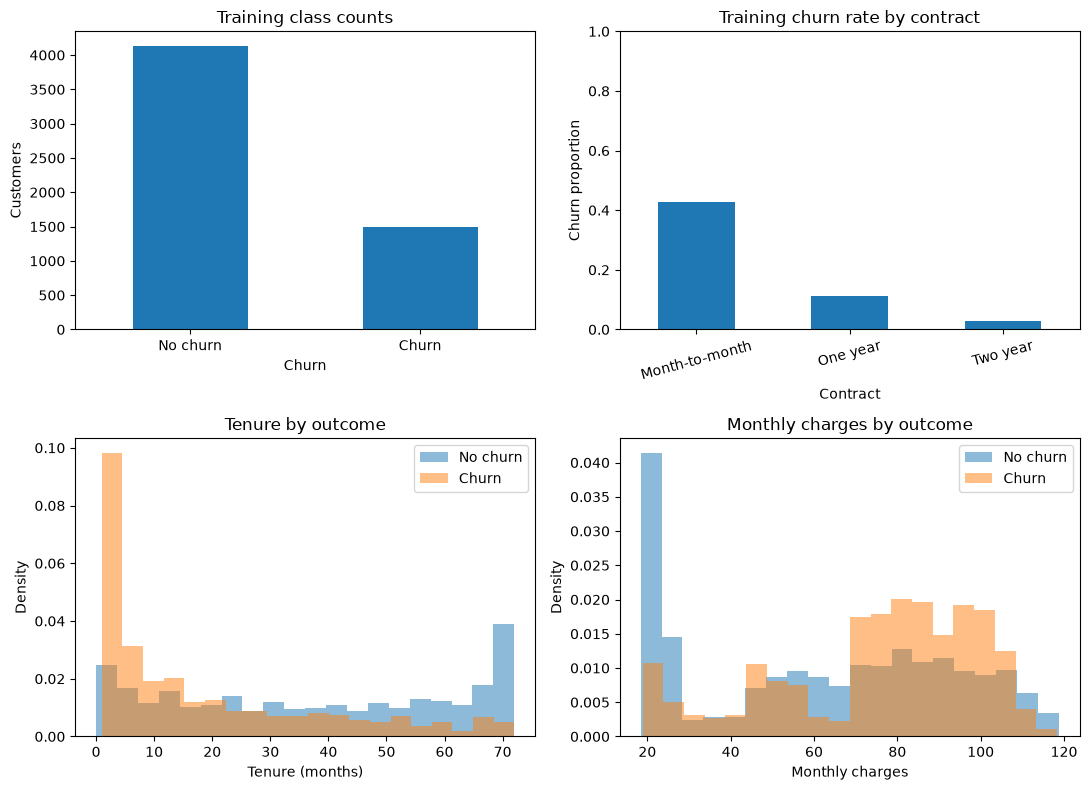

Observed training churn: month-to-month 42.7%, two-year 2.9%.
These are associations; contract choice and tenure may be confounded.
{'training_equal_predictor_rows': 26, 'training_label_ambiguous_profiles': 11, 'policy': 'Retain distinct customer IDs; matching attributes do not establish repeated persons.'}


In [3]:
X = raw.drop(columns=["customerID", "Churn"]).copy()
y = raw["Churn"].map({"No": 0, "Yes": 1})
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED,
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(raw)
print(f"Training: {len(X_train)}; test: {len(X_test)}")
print(f"Training churn prevalence: {y_train.mean():.3%}")
train = clean_features(X_train).assign(Churn=y_train)
display(train[["tenure", "MonthlyCharges", "TotalCharges"]].describe())
display(train.groupby("Contract")["Churn"].agg(customers="size", churn_rate="mean"))
display(train.groupby("InternetService")["Churn"].agg(customers="size", churn_rate="mean"))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
y_train.value_counts().reindex([0, 1]).plot.bar(ax=axes[0, 0], rot=0)
axes[0, 0].set(xticklabels=["No churn", "Churn"], title="Training class counts", ylabel="Customers")
train.groupby("Contract")["Churn"].mean().plot.bar(ax=axes[0, 1], rot=15)
axes[0, 1].set(title="Training churn rate by contract", ylabel="Churn proportion", ylim=(0, 1))
for target, label in [(0, "No churn"), (1, "Churn")]:
    train.loc[train.Churn.eq(target), "tenure"].plot.hist(
        ax=axes[1, 0], bins=20, alpha=0.5, density=True, label=label)
    train.loc[train.Churn.eq(target), "MonthlyCharges"].plot.hist(
        ax=axes[1, 1], bins=20, alpha=0.5, density=True, label=label)
axes[1, 0].set(title="Tenure by outcome", xlabel="Tenure (months)", ylabel="Density")
axes[1, 1].set(title="Monthly charges by outcome", xlabel="Monthly charges", ylabel="Density")
axes[1, 0].legend()
axes[1, 1].legend()
fig.tight_layout()
fig.savefig(REPORTS / "training_eda.png", dpi=130)
plt.show()
contract_rates = train.groupby("Contract")["Churn"].mean()
print(f"Observed training churn: month-to-month {contract_rates['Month-to-month']:.1%}, "
      f"two-year {contract_rates['Two year']:.1%}.")
print("These are associations; contract choice and tenure may be confounded.")
feature_summary = pd.DataFrame({
    "missing": clean_features(X_train).isna().sum(),
    "distinct": clean_features(X_train).nunique(),
    "type": clean_features(X_train).dtypes.astype(str),
})
feature_summary.to_csv(REPORTS / "training_feature_summary.csv")
profiles = train.groupby(FEATURES, dropna=False)["Churn"].agg(["size", "nunique"])
profile_audit = {
    "training_equal_predictor_rows": int(train.duplicated(subset=FEATURES).sum()),
    "training_label_ambiguous_profiles": int(profiles["nunique"].gt(1).sum()),
    "policy": "Retain distinct customer IDs; matching attributes do not establish repeated persons.",
}
(REPORTS / "profile_audit.json").write_text(json.dumps(profile_audit, indent=2) + "\n")
print(profile_audit)


## 3. Data preparation

**Select and clean data.** Exclude `customerID` and the target. Convert
`TotalCharges` deterministically to numeric and `SeniorCitizen` to a binary
category. Keep all rows and the original service categories, including
`No internet service` and `No phone service`.

**Construct, integrate, and format.** No joins or domain-specific engineered features are needed
for this single-table baseline; a missing-charge indicator is added below. Use median imputation and standardization for
numeric features; most-frequent imputation and one-hot encoding for categorical
features. Schema-valid levels absent from a fitting fold are tolerated by the encoder. All learned transforms
live inside a pipeline and are refit independently in each training fold.
No resampling occurs outside cross-validation; balanced classifiers address
imbalance through training weights.

The saved pipeline accepts the **original 19 CSV predictor columns**, including
numeric/string `TotalCharges` and 0/1 `SeniorCitizen`. Deterministic normalization
is inside the pipeline, so training and prediction use the same input contract.
A missing-value indicator retains the information that a charge was absent;
imputation remains a baseline assumption rather than an asserted account balance.
The source table is neither merged nor augmented with synthetic customer records.

**Input contract and verification.** Unexpected categories, missing/extra columns,
negative/nonfinite charges, fractional tenure, and inconsistent service states
raise errors. Actual missing values are accepted and imputed. `handle_unknown`
in the encoder remains a fallback for schema-valid levels absent from a fitting
fold, not permission to ignore misspelled inputs. Below, each fitted fold's medians,
scaling means, and categorical levels are checked against that fold's training
rows, independently of validation and test rows.

In [4]:
numeric_features = NUMERIC.copy()
categorical_features = CATEGORICAL.copy()
assert len(numeric_features) + len(categorical_features) == 19
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_features),
])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4. Modeling

**Select techniques and design tests.** Compare a prior-probability dummy baseline,
unweighted and class-balanced logistic regression, and a shallow class-balanced decision tree.
Logistic regression offers a simple additive baseline; the tree allows nonlinear
splits with an explicit depth limit. Use the same shuffled stratified five folds
for each model. Select by mean validation average precision, with ROC AUC,
precision, recall, F1, and accuracy reported for context.

**Build and assess models.** Hyperparameters are fixed below to keep the study
small: logistic regression C=1 and max_iter=2000; tree max_depth=4 and
min_samples_leaf=30. There is no additional hyperparameter search. Fit only the
selected pipeline on all training rows after cross-validation. The 0.50 threshold
is fixed before evaluation and is not optimized using the test set.

Include unweighted logistic regression because class weights change the loss and
score calibration; minority-class prevalence alone does not justify balanced
weights. Save per-fold scores. Their standard deviations describe fold variation,
not confidence intervals or independent replicate experiments. AP chooses the
model for ranking; threshold recall criteria are separate descriptive checks.
Revisions use only training CV for selection. The historical test partition has
already been examined, so it is now a **reused benchmark**, not fresh confirmation.

**Model assessment and explanation.** Small differences in paired fold AP do not
establish statistically significant superiority. The rule selects a reproducible
candidate, not a universal best classifier. Export fitted coefficients for
inspection, noting that standardized numeric terms and redundant one-hot levels
have different interpretations; correlated tenure/charges and regularization
prevent causal or independent-factor conclusions. Class-weighted scores especially
should not be treated as calibrated population churn probabilities.

In [5]:
candidates = {
    "dummy_prior": DummyClassifier(strategy="prior"),
    "logistic_unweighted": LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    "logistic_balanced": LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED),
    "tree_balanced": DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {name: name for name in ["average_precision", "roc_auc", "recall", "f1", "accuracy"]}
# The dummy predicts no churn: precision is undefined and reported as zero.
scoring["precision"] = make_scorer(precision_score, zero_division=0)
pipelines = {}
cv_rows = []
fold_rows = []
fold_audits = []
for name, classifier in candidates.items():
    pipeline = Pipeline([("normalize", FunctionTransformer(clean_features, validate=False)),
                         ("prepare", clone(preprocessor)), ("model", classifier)])
    pipelines[name] = pipeline
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, error_score="raise", return_estimator=True)
    for fold, ((fit_rows, validation_rows), estimator) in enumerate(zip(cv.split(X_train, y_train), scores["estimator"]), start=1):
        assert set(fit_rows).isdisjoint(validation_rows)
        fold_train = clean_features(X_train.iloc[fit_rows])
        prepare = estimator.named_steps["prepare"]
        numeric = prepare.named_transformers_["numeric"]
        np.testing.assert_allclose(numeric.named_steps["impute"].statistics_, fold_train[numeric_features].median())
        imputed = numeric.named_steps["impute"].transform(fold_train[numeric_features])
        np.testing.assert_allclose(numeric.named_steps["scale"].mean_, imputed.mean(axis=0))
        encoder = prepare.named_transformers_["categorical"].named_steps["encode"]
        for column, levels in zip(categorical_features, encoder.categories_):
            assert set(levels) == set(fold_train[column].dropna().unique())
        fold_audits.append({"model": name, "fold": fold, "fit_rows": len(fit_rows),
                            "validation_rows": len(validation_rows), "training_only_transforms": True})
    row = {"model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = float(scores[f"test_{metric}"].mean())
        row[f"{metric}_std"] = float(scores[f"test_{metric}"].std())
    cv_rows.append(row)
    for fold in range(cv.n_splits):
        fold_rows.append({"model": name, "fold": fold + 1,
                          **{metric: float(scores[f"test_{metric}"][fold]) for metric in scoring}})
cv_results = pd.DataFrame(cv_rows).set_index("model").sort_values("average_precision_mean", ascending=False)
display(cv_results.round(4))
cv_results.to_csv(REPORTS / "cross_validation.csv")
best_name = cv_results.index[0]
best_model = clone(pipelines[best_name]).fit(X_train, y_train)
print("Selected by training CV average precision:", best_name)
pd.DataFrame(fold_rows).to_csv(REPORTS / "cross_validation_folds.csv", index=False)

pd.DataFrame(fold_audits).to_csv(REPORTS / "fold_preprocessing_audit.csv", index=False)
feature_names = best_model.named_steps["prepare"].get_feature_names_out()
fitted_classifier = best_model.named_steps["model"]
if hasattr(fitted_classifier, "coef_"):
    importance = pd.DataFrame({"feature": feature_names, "coefficient": fitted_classifier.coef_[0]})
    importance = importance.iloc[importance.coefficient.abs().sort_values(ascending=False).index]
else:
    importance = pd.DataFrame({"feature": feature_names, "importance": fitted_classifier.feature_importances_})
importance.to_csv(REPORTS / "model_terms.csv", index=False)
display(importance.head(10))
print("Terms describe the fitted classifier, not causal effects or stable independent risk factors.")


,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,recall_mean,recall_std,f1_mean,f1_std,accuracy_mean,accuracy_std,precision_mean,precision_std
model,,,,,,,,,,,,
logistic_unweighted,0.6617,0.0192,0.8463,0.0126,0.5431,0.0411,0.5921,0.0296,0.8019,0.0115,0.6523,0.0247
logistic_balanced,0.6598,0.0194,0.8460,0.0125,0.8020,0.0370,0.6286,0.0230,0.7487,0.0154,0.5172,0.0190
tree_balanced,0.6000,0.0218,0.8278,0.0107,0.7920,0.0589,0.6038,0.0111,0.7244,0.0205,0.4905,0.0225
dummy_prior,0.2654,0.0001,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.7346,0.0001,0.0000,0.0000


Selected by training CV average precision: logistic_unweighted


,feature,coefficient
0,numeric__tenure,-1.257594
40,categorical__Contract_Two year,-0.750265
18,categorical__InternetService_Fiber optic,0.648556
17,categorical__InternetService_DSL,-0.643629
1,numeric__MonthlyCharges,-0.597041
38,categorical__Contract_Month-to-month,0.578650
2,numeric__TotalCharges,0.528132
41,categorical__PaperlessBilling_No,-0.329349
19,categorical__InternetService_No,-0.291868
21,categorical__OnlineSecurity_No internet service,-0.291868


Terms describe the fitted classifier, not causal effects or stable independent risk factors.


## 5. Evaluation

**Evaluate results against objectives.** Evaluate the selected model on the
fixed, previously inspected test partition, using the fixed threshold. Compare ranking performance
against prevalence and a fitted dummy baseline. Inspect the confusion matrix,
precision-recall curve, and ROC curve; report the three predefined acceptance
checks rather than treating accuracy alone as success.

**Review the process and determine next steps.** Verify disjoint partitions,
pipeline-only learned preprocessing, consistent inference columns, and persisted
prediction equality. Report descriptive subgroup results as an audit prompt,
not evidence that the model is fair. This reused random split supplies a within-dataset
benchmark, not independent evidence of future performance. A dated external sample, cost estimates,
calibration assessment, feature availability review, and a controlled retention
trial are required before operational use.

**Uncertainty and comparison.** Report stratified bootstrap 95% percentile
intervals, conditional on the fitted model, observed class counts, and this reused
sample. These do not include model-selection uncertainty, temporal drift, or an
independent replication. Also show baseline accuracy and the actual contact/error
counts so small accuracy gains cannot be mistaken for retention value.

Probability reliability is described by the Brier score (squared probability
error) against a prior baseline and quantile-bin observed rates; these are
post-selection diagnostics, not calibration fitting or proof of calibration.
Top-20% review performance uses a fixed workload and stable tie ordering. Bootstrap
intervals condition on class counts and an IID-within-class assumption; household
or other dependence may invalidate that assumption. Subgroup recall intervals are
Wilson intervals, descriptive and unadjusted for multiple comparisons. Unequal
false-positive rates or imprecise intervals require investigation, not a fairness
verdict. Do not use these diagnostics to tune the model on this benchmark.

{
  "selected_model": "logistic_unweighted",
  "threshold": 0.5,
  "train_rows": 5634,
  "test_rows": 1409,
  "test_prevalence": 0.2654364797728886,
  "average_precision": 0.6342191206087134,
  "roc_auc": 0.8422589061975252,
  "precision": 0.658307210031348,
  "recall": 0.5614973262032086,
  "f1": 0.6060606060606061,
  "accuracy": 0.8062455642299503,
  "dummy_average_precision": 0.2654364797728886,
  "dummy_roc_auc": 0.5,
  "acceptance_checks": {
    "ap_above_prevalence": true,
    "roc_auc_at_least_080": true,
    "recall_at_least_060": false
  },
  "test_role": "reused benchmark; not independent confirmation",
  "dummy_accuracy": 0.7345635202271115,
  "confusion_counts": {
    "true_negative": 926,
    "false_positive": 109,
    "false_negative": 164,
    "true_positive": 210
  },
  "flagged_customers": 319,
  "flagged_fraction": 0.2264017033356991,
  "bootstrap_95_intervals": {
    "roc_auc": {
      "lower": 0.8202991875274483,
      "upper": 0.8644310108760237
    },
    "average

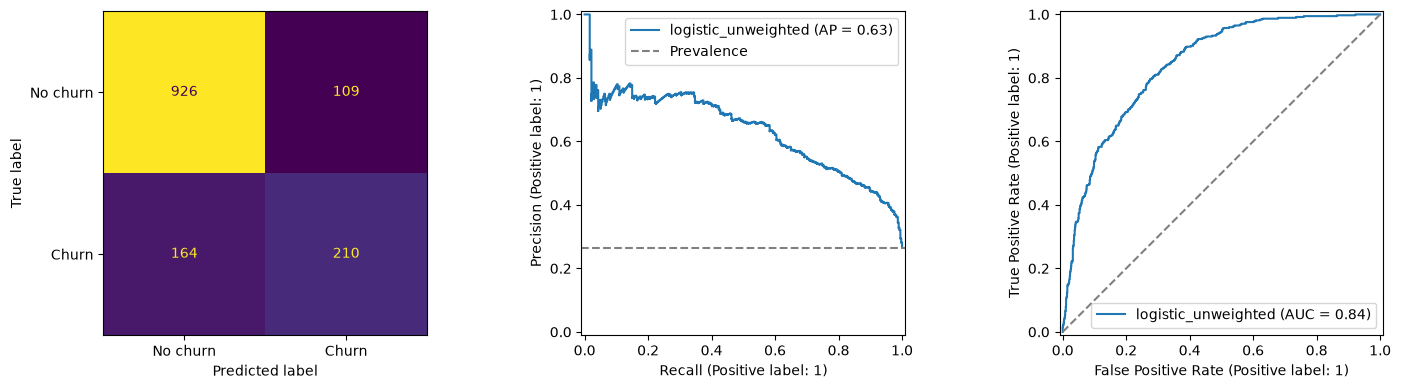

,field,group,customers,actual_churners,actual_nonchurners,true_positive,false_positive,flagged_customers,churn_prevalence,precision,recall,false_positive_rate,recall_95_lower,recall_95_upper
0,gender,Female,687,193,494,101,51,152,0.280932,0.664474,0.523316,0.103239,0.453087,0.592635
1,gender,Male,722,181,541,109,58,167,0.250693,0.652695,0.602210,0.107209,0.529495,0.670676
2,SeniorCitizen,No,1187,276,911,145,80,225,0.232519,0.644444,0.525362,0.087816,0.466507,0.583521
3,SeniorCitizen,Yes,222,98,124,65,29,94,0.441441,0.691489,0.663265,0.233871,0.565115,0.749099


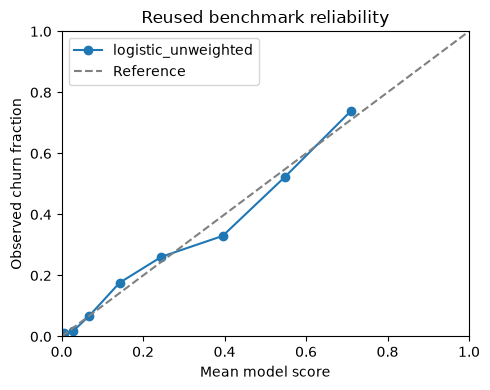

Illustrative top-20% review: {'customers': 282, 'known_churners': 187, 'precision': 0.6631205673758865, 'recall': 0.5, 'lift_over_random': 2.49822695035461}
Brier score (lower is better): 0.13799282477151062 ; prior baseline: 0.1949799619120813
Technical study gate: NOT MET
Decision: offline demonstration only; business acceptance is unresolved.


In [6]:
test_probability = best_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)
assert np.isfinite(test_probability).all()
assert ((test_probability >= 0) & (test_probability <= 1)).all()
baseline = clone(pipelines["dummy_prior"]).fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
metrics = {
    "selected_model": best_name, "threshold": THRESHOLD,
    "train_rows": len(X_train), "test_rows": len(X_test),
    "test_prevalence": float(y_test.mean()),
    "average_precision": float(average_precision_score(y_test, test_probability)),
    "roc_auc": float(roc_auc_score(y_test, test_probability)),
    "precision": float(precision_score(y_test, test_prediction, zero_division=0)),
    "recall": float(recall_score(y_test, test_prediction, zero_division=0)),
    "f1": float(f1_score(y_test, test_prediction, zero_division=0)),
    "accuracy": float(accuracy_score(y_test, test_prediction)),
    "dummy_average_precision": float(average_precision_score(y_test, baseline_probability)),
    "dummy_roc_auc": float(roc_auc_score(y_test, baseline_probability)),
}
checks = {
    "ap_above_prevalence": metrics["average_precision"] > metrics["test_prevalence"],
    "roc_auc_at_least_080": metrics["roc_auc"] >= 0.80,
    "recall_at_least_060": metrics["recall"] >= 0.60,
}
metrics["acceptance_checks"] = checks
tn, fp, fn, tp = confusion_matrix(y_test, test_prediction).ravel()
metrics.update({"test_role": "reused benchmark; not independent confirmation",
                "dummy_accuracy": float(accuracy_score(y_test, baseline.predict(X_test))),
                "confusion_counts": {"true_negative": int(tn), "false_positive": int(fp),
                                     "false_negative": int(fn), "true_positive": int(tp)},
                "flagged_customers": int(test_prediction.sum()),
                "flagged_fraction": float(test_prediction.mean())})
rng = np.random.default_rng(SEED)
labels = y_test.to_numpy()
class_positions = [np.flatnonzero(labels == label) for label in [0, 1]]
bootstrap = []
for _ in range(500):
    sample = np.concatenate([rng.choice(pos, size=len(pos), replace=True) for pos in class_positions])
    yt, yp = labels[sample], test_probability[sample]
    pred = yp >= THRESHOLD
    bootstrap.append([roc_auc_score(yt, yp), average_precision_score(yt, yp),
                      precision_score(yt, pred, zero_division=0), recall_score(yt, pred, zero_division=0)])
intervals = {}
for column, metric in enumerate(["roc_auc", "average_precision", "precision", "recall"]):
    lower, upper = np.quantile(np.asarray(bootstrap)[:, column], [0.025, 0.975])
    intervals[metric] = {"lower": float(lower), "upper": float(upper)}
metrics["bootstrap_95_intervals"] = intervals
print(json.dumps(metrics, indent=2))
print(classification_report(y_test, test_prediction, target_names=["No churn", "Churn"], zero_division=0))
classification = classification_report(y_test, test_prediction, target_names=["No churn", "Churn"], output_dict=True, zero_division=0)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=["No churn", "Churn"], ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(y_test, test_probability, ax=axes[1], name=best_name)
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label="Prevalence")
axes[1].legend()
RocCurveDisplay.from_predictions(y_test, test_probability, ax=axes[2], name=best_name)
axes[2].plot([0, 1], [0, 1], "--", color="gray")
fig.tight_layout()
fig.savefig(REPORTS / "test_evaluation.png", dpi=130)
plt.show()
# Equal feature vectors across partitions do not establish shared persons, but
# they qualify an independence claim and are retained as a documented limitation.
train_hash = pd.util.hash_pandas_object(clean_features(X_train), index=False)
test_hash = pd.util.hash_pandas_object(clean_features(X_test), index=False)
profile_audit["test_profiles_matching_a_training_profile"] = int(test_hash.isin(set(train_hash)).sum())
(REPORTS / "profile_audit.json").write_text(json.dumps(profile_audit, indent=2) + "\n")
subgroups = []
for field in ["gender", "SeniorCitizen"]:
    for value in sorted(clean_features(X_test)[field].unique()):
        mask = clean_features(X_test)[field].eq(value)
        subgroups.append({"field": field, "group": value, "customers": int(mask.sum()),
                          "actual_churners": int(y_test[mask].sum()),
                          "actual_nonchurners": int((1-y_test[mask]).sum()),
                          "true_positive": int(((test_prediction == 1) & (labels == 1) & mask.to_numpy()).sum()),
                          "false_positive": int(((test_prediction == 1) & (labels == 0) & mask.to_numpy()).sum()),
                          "flagged_customers": int(test_prediction[mask].sum()),
                          "churn_prevalence": float(y_test[mask].mean()),
                          "precision": float(precision_score(y_test[mask], test_prediction[mask], zero_division=0)),
                          "recall": float(recall_score(y_test[mask], test_prediction[mask], zero_division=0))})
subgroup_results = pd.DataFrame(subgroups)
def wilson_interval(successes, total):
    if total == 0:
        return float("nan"), float("nan")
    z = 1.959963984540054
    proportion = successes / total
    denominator = 1 + z*z/total
    center = (proportion + z*z/(2*total)) / denominator
    margin = z * np.sqrt(proportion*(1-proportion)/total + z*z/(4*total*total)) / denominator
    return center - margin, center + margin
subgroup_results["false_positive_rate"] = subgroup_results.false_positive / subgroup_results.actual_nonchurners
bounds = [wilson_interval(row.true_positive, row.actual_churners) for row in subgroup_results.itertuples()]
subgroup_results["recall_95_lower"] = [b[0] for b in bounds]
subgroup_results["recall_95_upper"] = [b[1] for b in bounds]
display(subgroup_results)
subgroup_results.to_csv(REPORTS / "subgroup_metrics.csv", index=False)
# Capacity is an illustrative fixed fraction, not a test-optimized threshold.
review_fraction = 0.20
review_count = int(np.ceil(len(y_test) * review_fraction))
ranked = np.argsort(-test_probability, kind="stable")[:review_count]
review_churners = int(labels[ranked].sum())
metrics["illustrative_top20_review"] = {
    "customers": review_count, "known_churners": review_churners,
    "precision": review_churners / review_count,
    "recall": review_churners / int(labels.sum()),
    "lift_over_random": (review_churners / review_count) / float(y_test.mean()),
}
metrics["brier_score"] = float(brier_score_loss(y_test, test_probability))
metrics["dummy_brier_score"] = float(brier_score_loss(y_test, baseline_probability))
observed, mean_score = calibration_curve(y_test, test_probability, n_bins=8, strategy="quantile")
pd.DataFrame({"mean_score": mean_score, "observed_churn_fraction": observed}).to_csv(
    REPORTS / "reliability_bins.csv", index=False)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(mean_score, observed, "o-", label=best_name)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Reference")
ax.set(xlabel="Mean model score", ylabel="Observed churn fraction", title="Reused benchmark reliability", xlim=(0,1), ylim=(0,1))
ax.legend()
fig.tight_layout()
fig.savefig(REPORTS / "score_reliability.png", dpi=130)
plt.show()
print("Illustrative top-20% review:", metrics["illustrative_top20_review"])
print("Brier score (lower is better):", metrics["brier_score"], "; prior baseline:", metrics["dummy_brier_score"])
(REPORTS / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
(REPORTS / "classification_report.json").write_text(json.dumps(classification, indent=2) + "\n")
print("Technical study gate:", "PASS" if all(checks.values()) else "NOT MET")
print("Decision: offline demonstration only; business acceptance is unresolved.")

## 6. Deployment

**Plan deployment and produce the final report.** Demonstrate local batch inference
with a saved preprocessing-and-model pipeline. Retain the training-only model;
do not refit on the holdout. Store the dataset checksum, package versions,
feature schema, split membership, predictions, metrics, and figures. The report
artifacts and this executed notebook document the results.

**Simple prediction demonstration.** Reload the artifact and score five held-out
customer profiles as examples, without using their labels as inputs. Verify exact
agreement with the in-memory model. Scores are model estimates, not calibrated
probabilities or evidence that an intervention will work. Only load trusted joblib
files because deserialization can execute code.

**Monitoring, maintenance, and project review.** For a future service, validate
schema and missing/category rates, monitor score distributions and subgroup
outcomes, and track delayed-label AP, recall, precision, and calibration. Review
monthly with a retention owner; investigate drift before retraining on a versioned,
dated dataset. Choose outreach thresholds using actual costs and capacity on
validation data. Roll back if data contracts fail or prospective performance
falls below approved criteria. This notebook supplies a local prediction example,
not a hosted service or a demonstrated retention intervention.

**Handoff and decision.** The deliverable is a reproducible analytical report and
local batch-scoring demonstration. Operational release is **not approved**:
future labels, pre-churn feature timestamps, an eligible population, cost/consent
policy, named operational owners, and prospective validation are absent. Suggested
roles above are proposals, not actual assigned personnel. Do not automatically
send offers or deploy a scoring service from these artifacts.

**Reproducible handoff.** Retain `src/telco.py` beside the model; it supplies the
serialized normalization function. `python CRISP-DM/src/verify_project.py --execute`
uses the invoking Python interpreter for its kernel, reruns the notebook, and
checks raw/missing/malformed inference, artifact hashes, fitted transforms, and
recomputed metrics. The pinned project requirements record direct versions, not
a full transitive lock or a guarantee of cross-platform bitwise equivalence.

**Proposed maintenance triggers.** Reject schema/category violations before
scoring; an analyst must investigate and version any schema change. At a future
monthly review, the data owner should compare missingness, score distributions,
label latency and subgroup error rates with a dated approved baseline. The
business owner must set capacity and acceptable error/cost limits before release;
if those approved limits fail, stop outreach and investigate before retraining.
No numerical production drift limits are invented from this static sample.

**Project experience.** Preserving preprocessing is essential to reusable scoring;
class weighting improves recall at one threshold while changing precision and
reliability. A good ranking metric does not settle the contact decision. Repeated
inspection consumes test independence; the next study needs new temporal evidence.
The final decision is saved in `reports/decision.json`.

In [7]:
model_path = OUTPUTS / "churn_pipeline.joblib"
joblib.dump(best_model, model_path)
loaded_model = joblib.load(model_path)
reloaded_probability = loaded_model.predict_proba(X_test)[:, 1]
np.testing.assert_allclose(reloaded_probability, test_probability, rtol=0, atol=0)
example_profiles = X_test.head(5).copy()
assert list(example_profiles.columns) == FEATURES
example_probability = loaded_model.predict_proba(example_profiles)[:, 1]
demonstration = pd.DataFrame({
    "example": np.arange(1, 6),
    "churn_score": example_probability,
    "predicted_churn": np.where(example_probability >= THRESHOLD, "Yes", "No"),
})
display(demonstration)
demonstration.to_csv(REPORTS / "prediction_demo.csv", index=False)
example_profiles.to_csv(OUTPUTS / "example_profiles.csv", index=False)
# Row indices refer to the immutable, checksummed source CSV; identifiers stay local.
pd.DataFrame({"source_row": X_test.index, "actual_churn": y_test.to_numpy(),
              "churn_score": test_probability, "predicted_churn": test_prediction}).to_csv(
    OUTPUTS / "test_predictions.csv", index=False)
manifest = {
    "dataset": "blastchar/telco-customer-churn", "dataset_version": 1,
    "analysis_scope": "retrospective classification; reused test benchmark",
    "source_url": DATASET_URL, "download_url": DOWNLOAD_URL, "sha256": source_hash,
    "python": platform.python_version(), "random_seed": SEED,
    "packages": {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient", "ipykernel", "jupyterlab"]},
    "features": list(X.columns), "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "train_source_rows": X_train.index.tolist(), "test_source_rows": X_test.index.tolist(),
    "selected_model": best_name, "threshold": THRESHOLD,
    "bootstrap": {"replicates": 500, "seed": SEED, "method": "stratified percentile; conditional on fitted model and class counts"},
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
    "normalization_source_sha256": hashlib.sha256((PROJECT / "src/telco.py").read_bytes()).hexdigest(),
    "notebook_code_sha256": hashlib.sha256("\n\n".join(
        cell["source"] if isinstance(cell["source"], str) else "".join(cell["source"])
        for cell in json.loads((PROJECT / "notebooks/telco_churn_crisp_dm.ipynb").read_text())["cells"]
        if cell["cell_type"] == "code").encode()).hexdigest(),
}
(OUTPUTS / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
# A compact public provenance record excludes row membership and local paths.
public_manifest = {k: v for k, v in manifest.items() if k not in ["train_source_rows", "test_source_rows"]}
(REPORTS / "provenance.json").write_text(json.dumps(public_manifest, indent=2) + "\n")
print("Verified persisted-model prediction equality on all test records.")
print("Local artifacts:", ", ".join(p.name for p in sorted(OUTPUTS.iterdir()) if p.name != ".gitkeep"))
print("Reports:", ", ".join(p.name for p in sorted(REPORTS.iterdir())))
# Pin directly used packages for replay; transitive dependencies remain resolver-managed.
replay_packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "joblib", "nbformat", "nbclient", "ipykernel", "jupyterlab"]
(PROJECT / "requirements.txt").write_text(
    "# Python 3.11; directly used packages from the verified run (not a complete lockfile).\n" +
    "".join(f"{package}=={version(package)}\n" for package in replay_packages))

schema = {"input_columns": FEATURES, "numeric_nonnegative": NUMERIC,
          "whole_months": ["tenure"],
          "categories_after_normalization": {key: sorted(value) for key, value in CATEGORY_VALUES.items()},
          "missing_values": "imputed using fitted training statistics",
          "unknown_categories": "reject; schema-valid fold-unseen levels use encoder fallback",
          "target_and_customer_id": "not accepted as inputs"}
(REPORTS / "input_contract.json").write_text(json.dumps(schema, indent=2) + "\n")
decision = {
    "analytical_use": "offline educational classification and local scoring only",
    "technical_point_checks": checks,
    "business_success": "not established: no intervention outcomes or costs",
    "operational_release": "not approved",
    "next_steps": ["Define eligible population, scoring date and prospective outcome window with a business owner",
                   "Obtain timestamped pre-outcome predictors and independent dated evaluation data",
                   "Choose threshold/capacity and assess calibration using new validation data and real costs",
                   "Review subgroup errors and consent policy, then test incremental benefit in a randomized pilot"],
}
(REPORTS / "decision.json").write_text(json.dumps(decision, indent=2) + "\n")


,example,churn_score,predicted_churn
0,1,0.046378,No
1,2,0.684174,Yes
2,3,0.059066,No
3,4,0.401902,No
4,5,0.021711,No


Verified persisted-model prediction equality on all test records.
Local artifacts: churn_pipeline.joblib, example_profiles.csv, run_manifest.json, test_predictions.csv
Reports: classification_report.json, cross_validation.csv, cross_validation_folds.csv, data_quality.csv, decision.json, fold_preprocessing_audit.csv, input_contract.json, metrics.json, model_terms.csv, prediction_demo.csv, profile_audit.json, provenance.json, reliability_bins.csv, review_log.md, score_reliability.png, subgroup_metrics.csv, test_evaluation.png, training_eda.png, training_feature_summary.csv


745

In [8]:
print("Final assessment: reproducible retrospective study; operational business value unverified.")
print(f"Selected model: {best_name}; CV AP: {cv_results.loc[best_name, 'average_precision_mean']:.3f}.")
print(f"Reused test AP: {metrics['average_precision']:.3f}; ROC AUC: {metrics['roc_auc']:.3f}; "
      f"precision: {metrics['precision']:.3f}; recall: {metrics['recall']:.3f}.")
print(f"Flagged {metrics['flagged_customers']} customers; false positives {fp}; missed churners {fn}.")
print("Scores are uncalibrated; equal subgroup performance and future retention benefit are not established.")

Final assessment: reproducible retrospective study; operational business value unverified.
Selected model: logistic_unweighted; CV AP: 0.662.
Reused test AP: 0.634; ROC AUC: 0.842; precision: 0.658; recall: 0.561.
Flagged 319 customers; false positives 109; missed churners 164.
Scores are uncalibrated; equal subgroup performance and future retention benefit are not established.
